## 1-2. Данные, модель и целевая функция

In [131]:

import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from joblib import parallel_config
from scipy.io import arff
from scipy.stats import loguniform, norm, randint, uniform
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=UserWarning)

In [132]:
!wget https://www.openml.org/data/download/1390080/phpuZu33P

--2026-10-02 23:25:23--  https://www.openml.org/data/download/1390080/phpuZu33P
Resolving www.openml.org (www.openml.org)... 131.155.10.137
Connecting to www.openml.org (www.openml.org)|131.155.10.137|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6211769 (5.9M) [text/plain]
Saving to: ‘phpuZu33P.8’

phpuZu33P.8         100%[===================>]   5.92M  6.56MB/s    in 0.9s    

2026-10-02 23:25:26 (6.56 MB/s) - ‘phpuZu33P.8’ saved [6211769/6211769]



In [133]:
data, meta = arff.loadarff("phpuZu33P")
df = pd.DataFrame(data)

df

,attr1,attr2,attr3,attr4,attr5,attr6,attr7,attr8,attr9,attr10,...,attr291,attr292,attr293,attr294,Beach,Sunset,FallFoliage,Field,Mountain,Urban
0,0.646467,0.666435,0.685047,0.699053,0.652746,0.407864,0.150309,0.535193,0.555689,0.580782,...,0.157332,0.247298,0.014025,0.029709,b'1',b'0',b'0',b'0',b'1',b'0'
1,0.770156,0.767255,0.761053,0.745630,0.742231,0.688086,0.708416,0.757351,0.760633,0.740314,...,0.251454,0.137833,0.082672,0.036320,b'1',b'0',b'0',b'0',b'0',b'1'
2,0.793984,0.772096,0.761820,0.762213,0.740569,0.734361,0.722677,0.849128,0.839607,0.812746,...,0.017166,0.051125,0.112506,0.083924,b'1',b'0',b'0',b'0',b'0',b'0'
3,0.938563,0.949260,0.955621,0.966743,0.968649,0.869619,0.696925,0.953460,0.959631,0.966320,...,0.019267,0.031290,0.049780,0.090959,b'1',b'0',b'0',b'0',b'0',b'0'
4,0.512130,0.524684,0.520020,0.504467,0.471209,0.417654,0.364292,0.562266,0.588592,0.584449,...,0.198151,0.238796,0.164270,0.184290,b'1',b'0',b'0',b'0',b'0',b'0'
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2402,0.875782,0.901653,0.926227,0.721366,0.795826,0.867642,0.794125,0.899067,0.908963,0.895336,...,0.215147,0.279607,0.254413,0.134350,b'0',b'0',b'0',b'0',b'0',b'1'
2403,0.657706,0.669877,0.692338,0.713920,0.727374,0.750354,0.684372,0.718770,0.719916,0.730645,...,0.217201,0.199491,0.048747,0.041638,b'0',b'0',b'0',b'0',b'0',b'1'
2404,0.952281,0.944987,0.905556,0.836604,0.875916,0.957034,0.953938,0.967956,0.819636,0.707311,...,0.028002,0.031900,0.017547,0.019734,b'0',b'0',b'0',b'0',b'0',b'1'
2405,0.883990,0.899004,0.901019,0.904298,0.846402,0.858145,0.851362,0.852472,0.876665,0.908187,...,0.239041,0.256158,0.226332,0.223070,b'0',b'0',b'0',b'0',b'0',b'1'


In [134]:
TARGET = "Urban"
df[TARGET] = df[TARGET].astype(int)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2407 entries, 0 to 2406
Columns: 300 entries, attr1 to Urban
dtypes: float64(294), int64(1), object(5)
memory usage: 5.5+ MB


In [135]:
X = df.drop([TARGET, "Beach", "Sunset", "FallFoliage", "Field", "Mountain"], axis=1)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
y.value_counts(normalize=True)

Urban
0    0.820939
1    0.179061
Name: proportion, dtype: float64

In [136]:
params = {
    "n_estimators": randint(50, 200),
    "max_depth": randint(2, 30),
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 20),
    "max_features": uniform(0.1, 0.9),
    "max_samples": uniform(0.3, 0.7),
    "min_impurity_decrease": loguniform(1e-6, 1e-2),
    "ccp_alpha": loguniform(1e-6, 1e-2),
}
log_params = ["min_impurity_decrease", "ccp_alpha"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

n_trials = 60
n_init = 25
seed = 0

In [137]:
def objective(point):
    model = RandomForestClassifier(**point, random_state=seed)
    with parallel_config(backend="threading", n_jobs=cv.get_n_splits()):
        return cross_val_score(model, X_train, y_train, cv=cv, scoring="f1").mean()


def encode(frame):
    Z = frame[list(params)].astype(float)
    Z[log_params] = np.log10(Z[log_params])
    return Z.to_numpy()

## 3. Случайный поиск

In [138]:
def random_search(n_trials: int, seed: int) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    tried = pd.DataFrame({
        name: dist.rvs(size=n_trials, random_state=rng.integers(2**31))
        for name, dist in params.items()
    })
    scores = []
    for point in tqdm(tried.to_dict("records")):
        scores.append(objective(point))
    return tried.assign(score=scores, step=range(1, n_trials + 1))

## 3. Байесовская оптимизация

In [139]:
from sklearn.ensemble import RandomForestRegressor


def bayesian_optimization(n_trials: int, seed: int, n_init: int=n_init, n_candidates: int=2000):
    rng = np.random.default_rng(seed)
    surrogate = RandomForestRegressor(
        n_estimators=200, min_samples_leaf=2, random_state=seed
    )
    tried = pd.DataFrame({
        name: dist.rvs(size=n_init, random_state=rng.integers(2**31))
        for name, dist in params.items()
    })
    scores = []
    bar = tqdm(total=n_trials)

    for point in tried.to_dict("records"):
        scores.append(objective(point))
        bar.update()

    for i in range(n_trials - n_init):
        surrogate.fit(encode(tried), scores)
        candidates = pd.DataFrame({
            name: dist.rvs(size=n_candidates, random_state=rng.integers(2**31))
            for name, dist in params.items()
        })
        grid = encode(candidates)
        leaves = np.array([tree.predict(grid) for tree in surrogate.estimators_])
        mu, sigma = leaves.mean(axis=0), leaves.std(axis=0) + 1e-9
        z = (mu - max(scores)) / sigma
        expected_improvement = (mu - max(scores)) * norm.cdf(z) + sigma * norm.pdf(z)

        chosen = candidates.loc[[expected_improvement.argmax()]]
        tried = pd.concat([tried, chosen], ignore_index=True)
        scores.append(objective(chosen.to_dict("records")[0]))
        bar.update()

    bar.close()
    return tried.assign(score=scores, step=range(1, n_trials + 1))

In [140]:
random_search_trial_df = random_search(n_trials=n_trials, seed=seed)

100%|██████████| 60/60 [04:35<00:00,  4.60s/it]


In [141]:
bo_trial_df = bayesian_optimization(n_trials=n_trials, n_init=5, seed=seed, n_candidates=2000)

100%|██████████| 60/60 [06:15<00:00,  6.26s/it]


## 8. Optuna

In [142]:
def optuna_objective(trial):
    return objective({
        "n_estimators": trial.suggest_int("n_estimators", 50, 199),
        "max_depth": trial.suggest_int("max_depth", 2, 29),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 19),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 19),
        "max_features": trial.suggest_float("max_features", 0.1, 1.0),
        "max_samples": trial.suggest_float("max_samples", 0.3, 1.0),
        "min_impurity_decrease": trial.suggest_float("min_impurity_decrease", 1e-6, 1e-2, log=True),
        "ccp_alpha": trial.suggest_float("ccp_alpha", 1e-6, 1e-2, log=True),
    })

In [143]:
from optuna.samplers import TPESampler, GPSampler

sampler = GPSampler(seed=seed)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(optuna_objective, n_trials=n_trials)

optuna_random_trial_df = pd.DataFrame([trial.params for trial in study.trials])[list(params)].assign(
    score=[trial.value for trial in study.trials],
    step=range(1, n_trials + 1),
)

In [144]:
sampler = TPESampler(seed=seed)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(optuna_objective, n_trials=n_trials)

optuna_tpe_trial_df = pd.DataFrame([trial.params for trial in study.trials])[list(params)].assign(
    score=[trial.value for trial in study.trials],
    step=range(1, n_trials + 1),
)

## 4. Сравнение методов

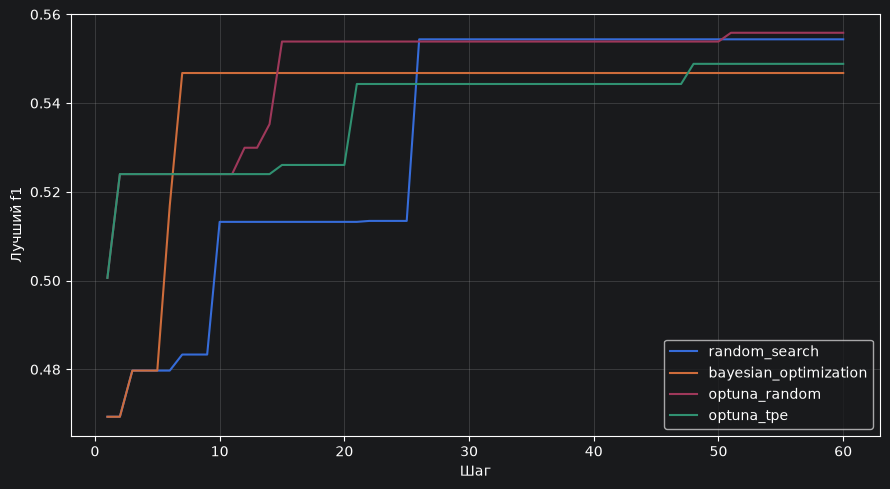

In [145]:
steps = np.arange(1, n_trials + 1)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(steps, random_search_trial_df["score"].cummax(), label="random_search")
ax.plot(steps, bo_trial_df["score"].cummax(), label="bayesian_optimization")
ax.plot(steps, optuna_random_trial_df["score"].cummax(), label="optuna_random")
ax.plot(steps, optuna_tpe_trial_df["score"].cummax(), label="optuna_tpe")

ax.set_xlabel("Шаг")
ax.set_ylabel("Лучший f1")

ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [146]:
to_remove = ["score", "step"]
rand_best_params = random_search_trial_df.drop(to_remove, axis=1).iloc[
    [random_search_trial_df["score"].argmax()]
].to_dict(orient="records")[0]

bo_best_params = bo_trial_df.drop(to_remove, axis=1).iloc[
    [bo_trial_df["score"].argmax()]
].to_dict(orient="records")[0]

optuna_best_params = optuna_random_trial_df.drop(to_remove, axis=1, errors="ignore").iloc[
    [optuna_random_trial_df["score"].argmax()]
].to_dict(orient="records")[0]

optuna_tpe_best_params = optuna_tpe_trial_df.drop(to_remove, axis=1, errors="ignore").iloc[
    [optuna_tpe_trial_df["score"].argmax()]
].to_dict(orient="records")[0]

random_search_model = RandomForestClassifier(**rand_best_params, random_state=seed)
bo_search_model = RandomForestClassifier(**bo_best_params, random_state=seed)
optuna_search_model = RandomForestClassifier(**optuna_best_params, random_state=seed)
optuna_tpe_search_model = RandomForestClassifier(**optuna_tpe_best_params, random_state=seed)

random_search_model.fit(X_train, y_train)
bo_search_model.fit(X_train, y_train)
optuna_search_model.fit(X_train, y_train)
optuna_tpe_search_model.fit(X_train, y_train)

print(f1_score(y_test, random_search_model.predict(X_test)))
print(f1_score(y_test, bo_search_model.predict(X_test)))
print(f1_score(y_test, optuna_search_model.predict(X_test)))
print(f1_score(y_test, optuna_tpe_search_model.predict(X_test)))

0.5039370078740157
0.5384615384615384
0.5671641791044776
0.515625


## 5. Целевая функция по шагам

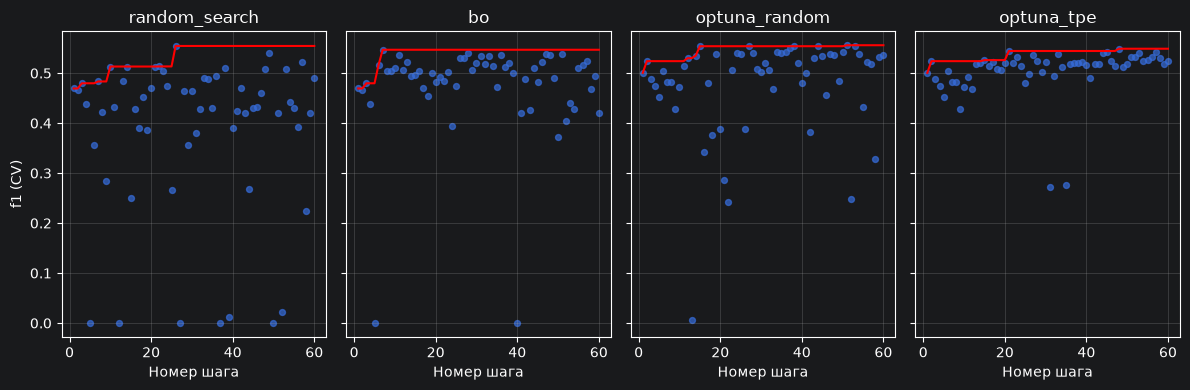

In [147]:
fig, axes = plt.subplots(1, 4, figsize=(12, 4), sharey=True)

runs = {
    "random_search": random_search_trial_df,
    "bo": bo_trial_df,
    "optuna_random": optuna_random_trial_df,
    "optuna_tpe": optuna_tpe_trial_df,
}
for ax, (name, history) in zip(axes, runs.items()):
    ax.scatter(history["step"], history["score"], s=18, alpha=0.7)
    ax.plot(history["step"], history["score"].cummax(), color="red")
    ax.set_title(name)
    ax.set_xlabel("Номер шага")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("f1 (CV)")
plt.tight_layout()
plt.show()

## 6. Пространство гиперпараметров

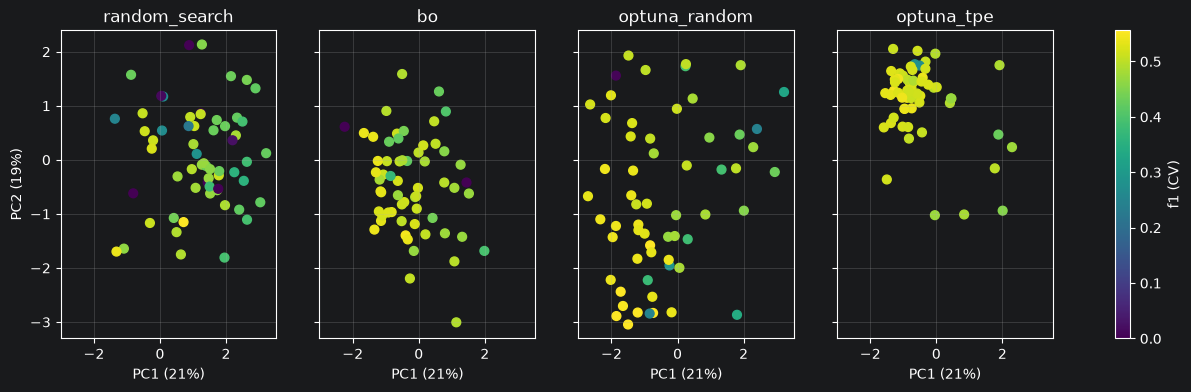

In [148]:
pooled = pd.concat(
    [history.assign(method=name) for name, history in runs.items()], ignore_index=True
)
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(StandardScaler().fit_transform(encode(pooled)))
ev = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, len(runs), figsize=(4 * len(runs), 4), sharex=True, sharey=True)
for ax, name in zip(axes, runs):
    mask = (pooled["method"] == name).to_numpy()
    sc = ax.scatter(
        P[mask, 0], P[mask, 1], c=pooled.loc[mask, "score"], cmap="viridis",
        vmin=pooled["score"].min(), vmax=pooled["score"].max(), s=40
    )
    ax.set_title(name)
    ax.set_xlabel(f"PC1 ({ev[0]:.0%})")
    ax.grid(alpha=0.3)
axes[0].set_ylabel(f"PC2 ({ev[1]:.0%})")
fig.colorbar(sc, ax=axes, label="f1 (CV)")
plt.show()

In [149]:
pd.DataFrame(pca.components_.T, index=list(params), columns=["PC1", "PC2"]).round(2)

,PC1,PC2
n_estimators,-0.22,-0.29
max_depth,0.17,-0.34
min_samples_split,0.02,0.61
min_samples_leaf,0.38,0.37
max_features,-0.16,0.50
max_samples,-0.52,0.05
min_impurity_decrease,0.39,-0.21
ccp_alpha,0.57,0.05


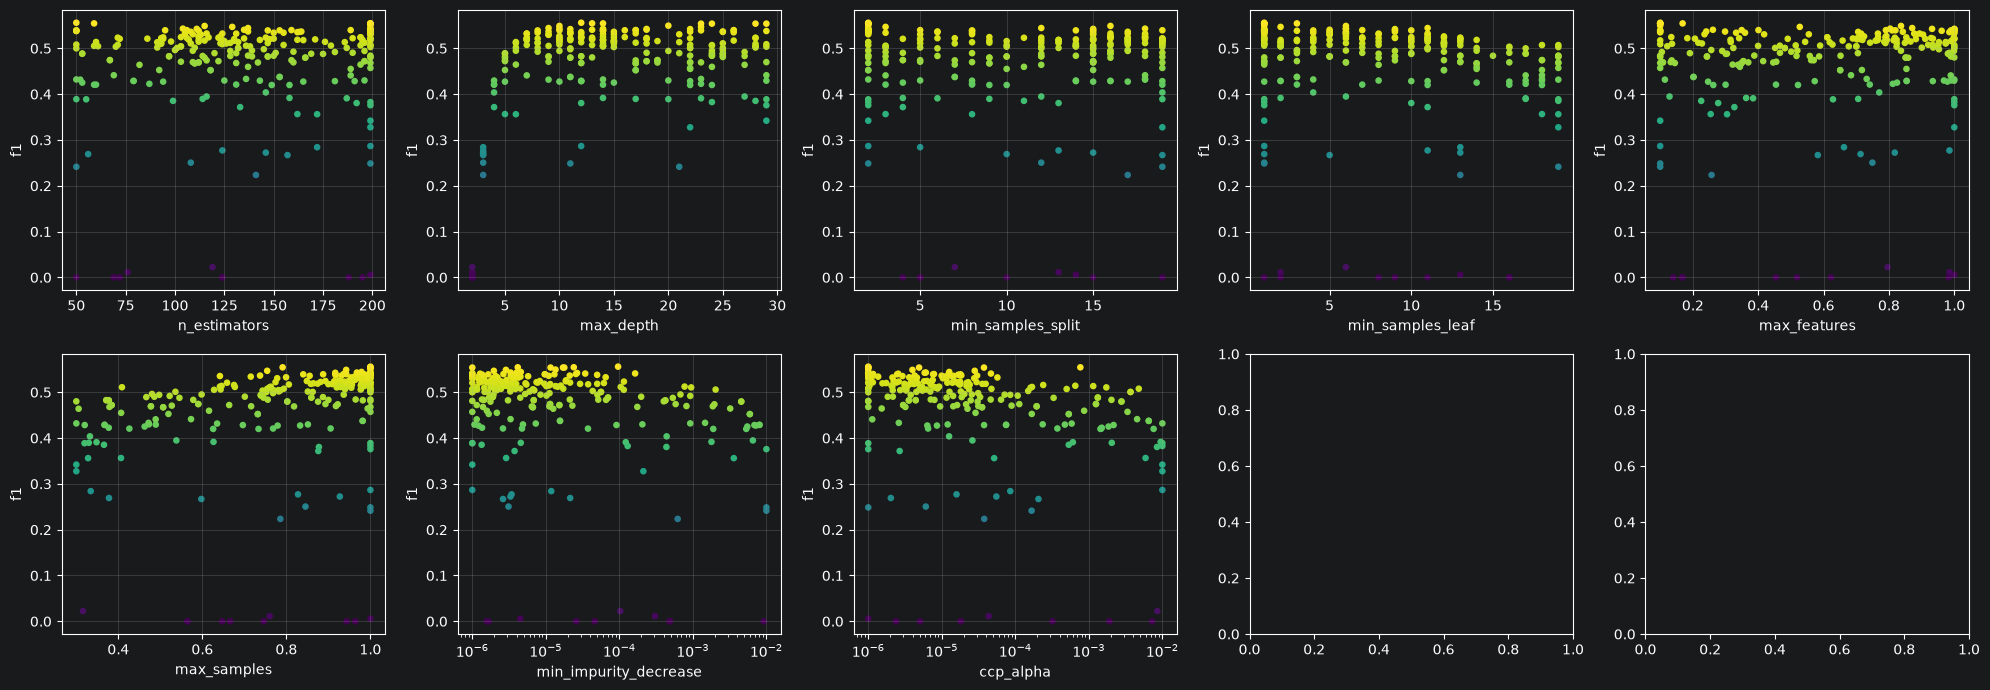

In [150]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, param in zip(axes.ravel(), params):
    ax.scatter(pooled[param], pooled["score"], c=pooled["score"], cmap="viridis", s=14)
    if param in log_params:
        ax.set_xscale("log")
    ax.set_xlabel(param)
    ax.set_ylabel("f1")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Важность гиперпараметров

In [151]:
importance = {}
for name, history in runs.items():
    Z, scores = encode(history), history["score"]
    forest = RandomForestRegressor(
        n_estimators=500, min_samples_leaf=2, random_state=seed, n_jobs=-1
    ).fit(Z, scores)
    perm = permutation_importance(forest, Z, scores, n_repeats=200, random_state=42, n_jobs=-1)
    importance[name] = np.clip(perm.importances_mean, 0, None)

importance = pd.DataFrame(importance, index=list(params))
importance = importance / importance.sum()
importance.round(3)


,random_search,bo,optuna_random,optuna_tpe
n_estimators,0.001,0.003,0.006,0.005
max_depth,0.959,0.914,0.149,0.707
min_samples_split,0.001,0.003,0.022,0.002
min_samples_leaf,0.014,0.015,0.123,0.013
max_features,0.000,0.004,0.018,0.016
max_samples,0.011,0.013,0.029,0.217
min_impurity_decrease,0.002,0.041,0.328,0.017
ccp_alpha,0.012,0.006,0.324,0.024


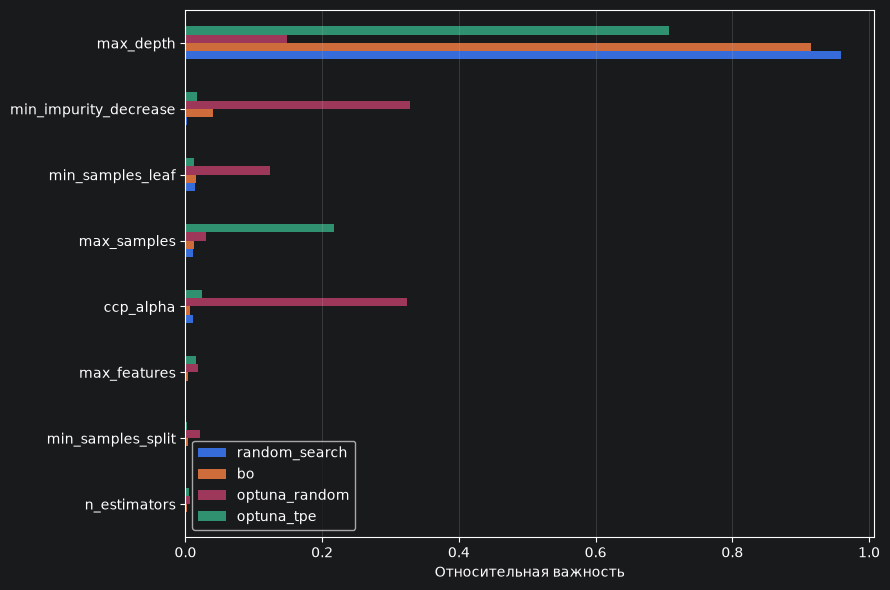

In [152]:
ax = importance.sort_values(importance.columns[1]).plot.barh(figsize=(9, 6))
ax.set_xlabel("Относительная важность")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()